# Load and Verify the Research Split

In [1]:

import os
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader 

from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, roc_auc_score


In [2]:

# Select GPU if available, otherwise use CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [3]:
DATA_ROOT = Path("/kaggle/input/datasets/francismon/curated-covid19-chest-xray-dataset/dataset")

SPLIT_FILE = Path("/kaggle/input/datasets/jamiulkawsar/curated-covid-chest-x-ray-csv-dataset/data_split.csv")

split_df = pd.read_csv(SPLIT_FILE)

print("Total images:", len(split_df))
print("\nColumns:")
print(split_df.columns.tolist())

print("\nFirst 5 rows:")
display(split_df.head())

Total images: 9208

Columns:
['path', 'label', 'class', 'split']

First 5 rows:


,path,label,class,split
0,train/2_Pneumonia/Pneumonia-Bacterial (1153).jpg,2,2_Pneumonia,train
1,train/0_Normal/Normal (1926).jpg,0,0_Normal,train
2,train/2_Pneumonia/Pneumonia-Viral (364).jpg,2,2_Pneumonia,train
3,train/2_Pneumonia/Pneumonia-Bacterial (973).jpg,2,2_Pneumonia,train
4,train/2_Pneumonia/Pneumonia-Bacterial (280).jpg,2,2_Pneumonia,train


In [4]:
sample_path = DATA_ROOT / split_df.iloc[0]["path"]

print("Sample image path:")
print(sample_path)

print("\nExists:", sample_path.exists())

Sample image path:
/kaggle/input/datasets/francismon/curated-covid19-chest-xray-dataset/dataset/train/2_Pneumonia/Pneumonia-Bacterial (1153).jpg

Exists: True


In [ ]:

classes = {
    "Normal": "0_Normal",
    "COVID-19": "1_Covid19",
    "Pneumonia": "2_Pneumonia"
}

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

# Main title
fig.suptitle(
    "Sample Images from the Curated COVID-19 Chest X-Ray Dataset",
    fontsize=16,
    fontweight="bold"
)

# First 3 rows: 4 images from each class
for row, (class_name, folder_name) in enumerate(classes.items()):
    image_paths = list(DATA_ROOT.rglob(f"{folder_name}/*.jpg"))[:4]

    for col, image_path in enumerate(image_paths):

        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(class_name, fontsize=12)

# Fourth row: mixed images from all 3 classes
mixed_images = []

for folder_name in classes.values():
    mixed_images.extend(list(DATA_ROOT.rglob(f"{folder_name}/*.jpg"))[:2])

for col, image_path in enumerate(mixed_images[:4]):

    image = Image.open(image_path)

    axes[3, col].imshow(image)
    axes[3, col].axis("off")
    axes[3, col].set_title("Mixed", fontsize=12)

# Leave space for the main title
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

# PyTorch Dataset Pipeline

In [ ]:
# create the pytorch dataset

class ChestXRayDataset(Dataset):

  def __init__(self, dataframe, data_root, transform = None):
    self.dataframe = dataframe.reset_index(drop = True)
    self.data_root = Path(data_root)
    self.transform = transform

  def __len__(self):
    return len(self.dataframe)

  def __getitem__(self, index):
    row = self.dataframe.iloc[index]

    image_path = self.data_root / row["path"]
    label = int(row["label"])

    image = Image.open(image_path).convert("RGB")
    if self.transform:
      image = self.transform(image)

    return image, label


In [ ]:
# craete the three obj
train_data = split_df[split_df["split"] == "train"]
val_data = split_df[split_df["split"] == "validation"]
test_data = split_df[split_df["split"] == "test"]

train_dataset = ChestXRayDataset(train_data, DATA_ROOT)
val_dataset = ChestXRayDataset(val_data, DATA_ROOT)
test_dataset = ChestXRayDataset(test_data, DATA_ROOT)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

In [ ]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Image size:", image.size)
print("Label:", label)

 # Image Preprocessing & Data Augmentation

In [ ]:
#Create the transform definitions

IMAGE_SIZE = 224
IMAGE_MEAN = [0.485, 0.456, 0.406]
IMAGE_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p = 0.5),
    transforms.RandomRotation(degrees = 10),
    transforms.ToTensor(),
    transforms.Normalize(mean = IMAGE_MEAN, std = IMAGE_STD)
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean = IMAGE_MEAN, std = IMAGE_STD)
])

In [ ]:
#Recreate the datasets
train_dataset = ChestXRayDataset(
    train_data,
    DATA_ROOT,
    transform = train_transform
)

val_dataset = ChestXRayDataset(
    val_data,
    DATA_ROOT,
    transform = val_test_transform
)

test_dataset = ChestXRayDataset(
    test_data,
    DATA_ROOT,
    transform = val_test_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
#

In [ ]:
#Test one sample
image, label = train_dataset[0]

print("Image type:", type(image))
print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Label:", label)

# PyTorch DataLoaders

In [ ]:
# Create DataLoaders

BATCH_SIZE = 32


#train loader
train_loader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True,
    num_workers = 2
)

# validation loader
val_loader = DataLoader(
    val_dataset,
    batch_size = BATCH_SIZE,
    shuffle = False,
    num_workers = 2
)

# test loader
test_loader = DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE,
    shuffle = False,
    num_workers = 2
)

In [ ]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

In [ ]:

# Get one batch from the training DataLoader
images, labels = next(iter(train_loader))

# ImageNet normalization values
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Create 4x4 grid
fig, axes = plt.subplots(4, 4, figsize=(12, 12))

# Main title
fig.suptitle(
    "Sample Training Batch After Data Augmentation and Normalization",
    fontsize=16,
    fontweight="bold"
)

for i, ax in enumerate(axes.flat):

    image = images[i]

    # Undo normalization for visualization
    image = image * std + mean
    image = torch.clamp(image, 0, 1)

    # [C, H, W] → [H, W, C]
    image = image.permute(1, 2, 0)

    # Display image
    ax.imshow(image)
    ax.axis("off")

    # Class name
    class_names = ["Normal", "COVID-19", "Pneumonia"]
    ax.set_title(class_names[labels[i].item()])

# Leave space for the main title
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

# DenseNet121

In [ ]:
# =========================
# Experiment Configuration
# =========================

SEED = 42

IMAGE_SIZE = 224
BATCH_SIZE = 32

NUM_CLASSES = 3
LEARNING_RATE = 0.001
NUM_EPOCHS = 50

CLASS_NAMES = [
    "Normal",
    "COVID-19",
    "Pneumonia"
]

MODEL_NAME = "DenseNet121"

print("Model:", MODEL_NAME)
print("Number of classes:", NUM_CLASSES)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Number of epochs:", NUM_EPOCHS)

In [ ]:
# =========================
# Transfer Learning: DenseNet121
# =========================

densenet121 = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

print(densenet121.classifier)

In [ ]:
# =========================
# Freeze DenseNet121 Backbone
# =========================

for parameter in densenet121.parameters():
    parameter.requires_grad = False

# Replace the ImageNet classifier with our 3-class classifier
densenet121.classifier = nn.Linear(
    densenet121.classifier.in_features,
    NUM_CLASSES
)

# Move the model to GPU or CPU
densenet121 = densenet121.to(device)

print("DenseNet121 backbone frozen.")
print("New classifier:", densenet121.classifier)

In [ ]:
# =========================
# Frozen BatchNorm Layers
# =========================

def set_frozen_batchnorm_eval(model):
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

In [ ]:
# Set the model to training mode
densenet121.train()

# Keep frozen BatchNorm layers fixed
set_frozen_batchnorm_eval(densenet121)

# Verify trainable parameters
for name, parameter in densenet121.named_parameters():
    if parameter.requires_grad:
        print(name)

In [ ]:
# =========================
# Loss and Optimizer
# =========================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    densenet121.classifier.parameters(),
    lr=LEARNING_RATE
)

In [ ]:
# =========================
# Training One Epoch
# =========================

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()
    set_frozen_batchnorm_eval(model)

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
# =========================
# Validation One Epoch
# =========================

def val_one_epoch(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [23]:
# =========================
# Train DenseNet121
# =========================

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")

best_model_path = "/kaggle/working/best_densenet121_frozen.pth"

for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        densenet121,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = val_one_epoch(
        densenet121,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            densenet121.state_dict(),
            best_model_path
        )

        print("Best DenseNet121 Frozen model saved.")

Epoch [4/50] Train Loss: 0.1516 Train Acc: 0.9497 Val Loss: 0.1575 Val Acc: 0.9486
Best DenseNet121 Frozen model saved.
Epoch [5/50] Train Loss: 0.1378 Train Acc: 0.9548 Val Loss: 0.1472 Val Acc: 0.9508
Best DenseNet121 Frozen model saved.
Epoch [6/50] Train Loss: 0.1268 Train Acc: 0.9556 Val Loss: 0.1400 Val Acc: 0.9529
Best DenseNet121 Frozen model saved.
Epoch [7/50] Train Loss: 0.1255 Train Acc: 0.9584 Val Loss: 0.1357 Val Acc: 0.9573
Best DenseNet121 Frozen model saved.
Epoch [8/50] Train Loss: 0.1235 Train Acc: 0.9570 Val Loss: 0.1386 Val Acc: 0.9515
Epoch [9/50] Train Loss: 0.1191 Train Acc: 0.9590 Val Loss: 0.1374 Val Acc: 0.9537
Epoch [10/50] Train Loss: 0.1144 Train Acc: 0.9593 Val Loss: 0.1305 Val Acc: 0.9587
Best DenseNet121 Frozen model saved.
Epoch [11/50] Train Loss: 0.1107 Train Acc: 0.9612 Val Loss: 0.1474 Val Acc: 0.9508
Epoch [12/50] Train Loss: 0.1086 Train Acc: 0.9603 Val Loss: 0.1258 Val Acc: 0.9609
Best DenseNet121 Frozen model saved.
Epoch [13/50] Train Loss: 0.

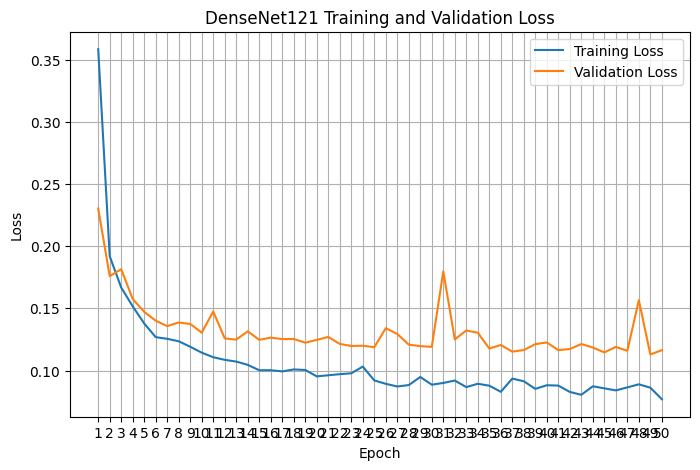

In [24]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet121 Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.savefig(
    "/kaggle/working/densenet121_frozen_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

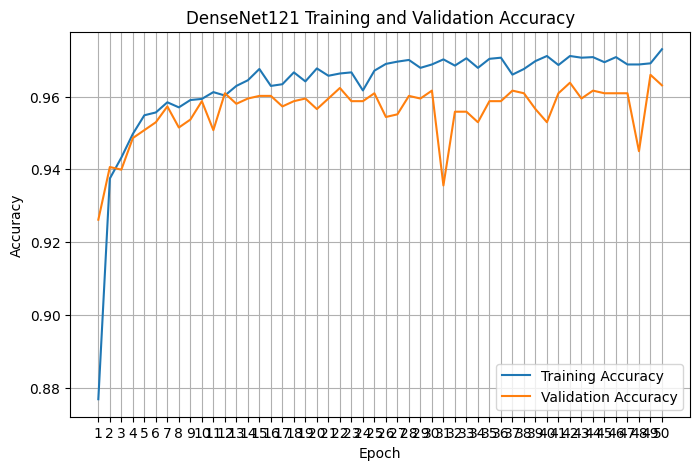

In [25]:
epochs = range(1, len(history["train_accuracy"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_accuracy"], label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DenseNet121 Training and Validation Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.savefig(
    "/kaggle/working/densenet121_frozen_training_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
# =========================
# Load Best DenseNet121
# =========================

densenet121 = models.densenet121(weights=None)

densenet121.classifier = nn.Linear(
    densenet121.classifier.in_features,
    NUM_CLASSES
)

densenet121.load_state_dict(
    torch.load(best_model_path, map_location=device)
)

densenet121 = densenet121.to(device)
densenet121.eval()

print("Best DenseNet121 checkpoint loaded successfully.")

Best DenseNet121 checkpoint loaded successfully.


In [27]:
# =========================
# Evaluation Function
# =========================

def evaluate_model(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            probabilities = torch.softmax(outputs, dim=1)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    loss = total_loss / total
    accuracy = correct / total

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    all_probabilities = np.array(all_probabilities)

    return (
        loss,
        accuracy,
        total,
        all_predictions,
        all_labels,
        all_probabilities
    )

In [28]:
# Evaluate on the validation set

val_loss, val_accuracy, total, all_predictions, all_labels, all_probabilities = evaluate_model(
    densenet121,
    val_loader,
    criterion,
    device
)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Samples: {total}")

print("Probability shape:", all_probabilities.shape)
print("Labels shape:", all_labels.shape)

Validation Loss: 0.1129
Validation Accuracy: 0.9660
Validation Accuracy: 96.60%
Validation Samples: 1381
Probability shape: (1381, 3)
Labels shape: (1381,)


In [29]:
# Classification report

report = classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

      Normal     0.9495    0.9592    0.9543       490
    COVID-19     0.9894    0.9740    0.9816       192
   Pneumonia     0.9713    0.9685    0.9699       699

    accuracy                         0.9660      1381
   macro avg     0.9701    0.9672    0.9686      1381
weighted avg     0.9661    0.9660    0.9660      1381



In [30]:
# Specificity for each class
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1, 2]
)

specificity = []

for i in range(len(CLASS_NAMES)):

    true_negative = (
        np.sum(cm)
        - np.sum(cm[i, :])
        - np.sum(cm[:, i])
        + cm[i, i]
    )

    false_positive = np.sum(cm[:, i]) - cm[i, i]

    denominator = true_negative + false_positive

    spec = (
        true_negative / denominator
        if denominator > 0
        else 0.0
    )

    specificity.append(spec)

for class_name, spec in zip(CLASS_NAMES, specificity):
    print(f"{class_name}: {spec:.4f} ({spec * 100:.2f}%)")

Normal: 0.9719 (97.19%)
COVID-19: 0.9983 (99.83%)
Pneumonia: 0.9707 (97.07%)


In [31]:
# =========================
# ROC Curve and AUC
# =========================

y_true = label_binarize(
    all_labels,
    classes=[0, 1, 2]
)

fpr = {}
tpr = {}
roc_auc = {}

for i in range(NUM_CLASSES):

    fpr[i], tpr[i], _ = roc_curve(
        y_true[:, i],
        all_probabilities[:, i]
    )

    roc_auc[i] = auc(fpr[i], tpr[i])

macro_auc = roc_auc_score(
    all_labels,
    all_probabilities,
    multi_class="ovr",
    average="macro"
)

for i, class_name in enumerate(CLASS_NAMES):
    print(f"{class_name} ROC-AUC: {roc_auc[i]:.4f}")

print(f"Macro-average ROC-AUC: {macro_auc:.4f}")

Normal ROC-AUC: 0.9931
COVID-19 ROC-AUC: 0.9978
Pneumonia ROC-AUC: 0.9947
Macro-average ROC-AUC: 0.9952


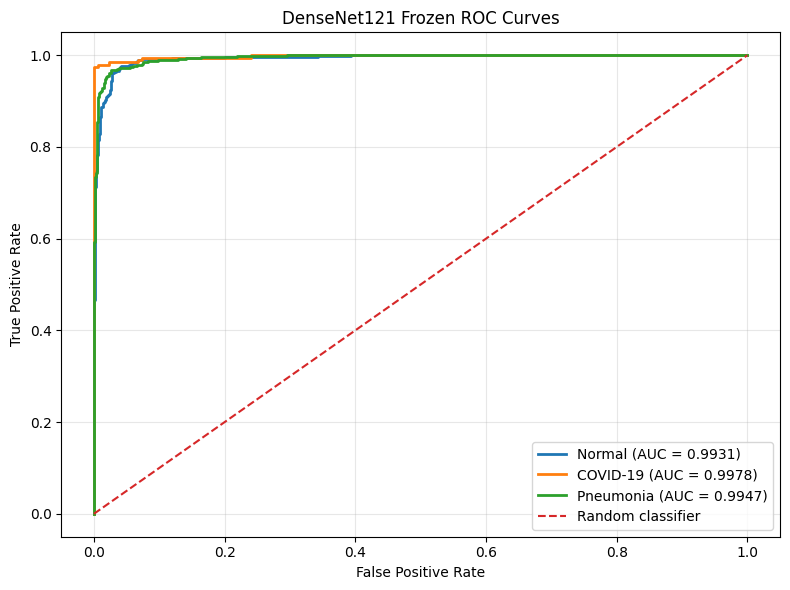

In [32]:
# Plot and save the ROC curves

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(CLASS_NAMES):

    plt.plot(
        fpr[i],
        tpr[i],
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc[i]:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("DenseNet121 Frozen ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/densenet121_frozen_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
# =========================
# Save Experiment Results
# =========================

results = {
    "model": MODEL_NAME,
    "validation_loss": val_loss,
    "validation_accuracy": val_accuracy,
    "macro_roc_auc": macro_auc,
}

for i, class_name in enumerate(CLASS_NAMES):
    results[f"{class_name}_roc_auc"] = roc_auc[i]
    results[f"{class_name}_specificity"] = specificity[i]

results_df = pd.DataFrame([results])

results_df.to_csv(
    "/kaggle/working/densenet121_frozen_results.csv",
    index=False
)

display(results_df)

,model,validation_loss,validation_accuracy,macro_roc_auc,Normal_roc_auc,Normal_specificity,COVID-19_roc_auc,COVID-19_specificity,Pneumonia_roc_auc,Pneumonia_specificity
0,DenseNet121,0.112942,0.965967,0.995207,0.993101,0.971942,0.997797,0.998318,0.994722,0.970674
